# **1. Perkenalan Dataset**


**Sumber Dataset**:  

Dataset yang digunakan dalam penelitian ini berasal dari Kaggle, yaitu US Health Insurance Dataset. Dataset ini banyak digunakan dalam studi dan pembelajaran machine learning yang berkaitan dengan analisis biaya asuransi kesehatan. Data ini menggambarkan hubungan antara karakteristik demografis dan gaya hidup individu terhadap besarnya biaya premi asuransi kesehatan.

Dataset ini terdiri dari 1338 data individu dengan 7 atribut, yaitu usia (age), jenis kelamin (sex), indeks massa tubuh (BMI), jumlah anak (children), status perokok (smoker), wilayah tempat tinggal (region), serta biaya asuransi kesehatan (charges) sebagai variabel target. Atribut dalam dataset ini mencakup fitur numerik dan kategorikal, sehingga memungkinkan dilakukan analisis eksploratif serta penerapan berbagai teknik preprocessing data.

Dataset ini relevan untuk penelitian analisis biaya asuransi kesehatan karena mencerminkan faktor-faktor utama yang digunakan dalam proses penilaian risiko (risk underwriting). Selain itu, dataset ini mendukung penerapan teknik machine learning, khususnya model regresi, untuk mempelajari hubungan antara karakteristik individu dan biaya premi asuransi kesehatan secara lebih akurat.

**Referensi data:**
https://www.kaggle.com/datasets/teertha/ushealthinsurancedataset




# **2. Import Library**

In [46]:
# Import library dasar
from pathlib import Path
import numpy as np
import pandas as pd

# Import library visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Import library preprocessing dan modeling
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Import library evaluasi dan model
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


# **3. Memuat Dataset**

Pada tahap ini, Anda perlu memuat dataset ke dalam notebook. Jika dataset dalam format CSV, Anda bisa menggunakan pustaka pandas untuk membacanya. Pastikan untuk mengecek beberapa baris awal dataset untuk memahami strukturnya dan memastikan data telah dimuat dengan benar.

Jika dataset berada di Google Drive, pastikan Anda menghubungkan Google Drive ke Colab terlebih dahulu. Setelah dataset berhasil dimuat, langkah berikutnya adalah memeriksa kesesuaian data dan siap untuk dianalisis lebih lanjut.

Jika dataset berupa unstructured data, silakan sesuaikan dengan format seperti kelas Machine Learning Pengembangan atau Machine Learning Terapan

In [47]:
file_candidates = [
    Path("../insurance_raw/insurance.csv"),
    Path("insurance_raw/insurance.csv")
]
file_path = next(path for path in file_candidates if path.exists())

try:
    df = pd.read_csv(file_path)
    print("Dataset berhasil dimuat dari local path.")
except Exception as e:
    print("Gagal memuat dataset:", e)

Dataset berhasil dimuat dari local path.


# **4. Exploratory Data Analysis (EDA)**

Pada tahap ini, Anda akan melakukan **Exploratory Data Analysis (EDA)** untuk memahami karakteristik dataset.

Tujuan dari EDA adalah untuk memperoleh wawasan awal yang mendalam mengenai data dan menentukan langkah selanjutnya dalam analisis atau pemodelan.

In [48]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [50]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [51]:
#Cek missing value
print("Jumlah missing value sebelum preprocessing:")
df.isnull().sum()

Jumlah missing value sebelum preprocessing:


,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


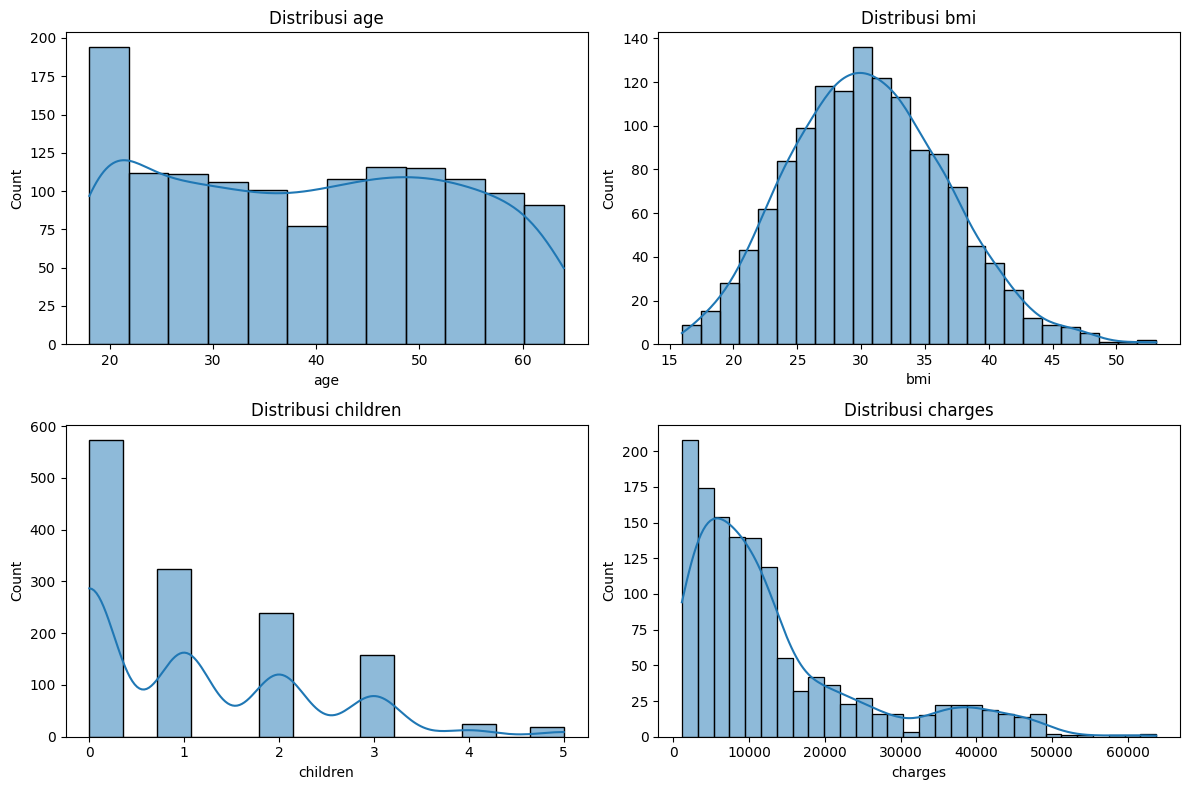

In [52]:
#Distribusi Data Numerik
numerical_cols = ["age", "bmi", "children", "charges"]

plt.figure(figsize=(12, 8))
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(2, 2, i)
    sns.histplot(df[col], kde=True)
    plt.title(f"Distribusi {col}")

plt.tight_layout()
plt.show()


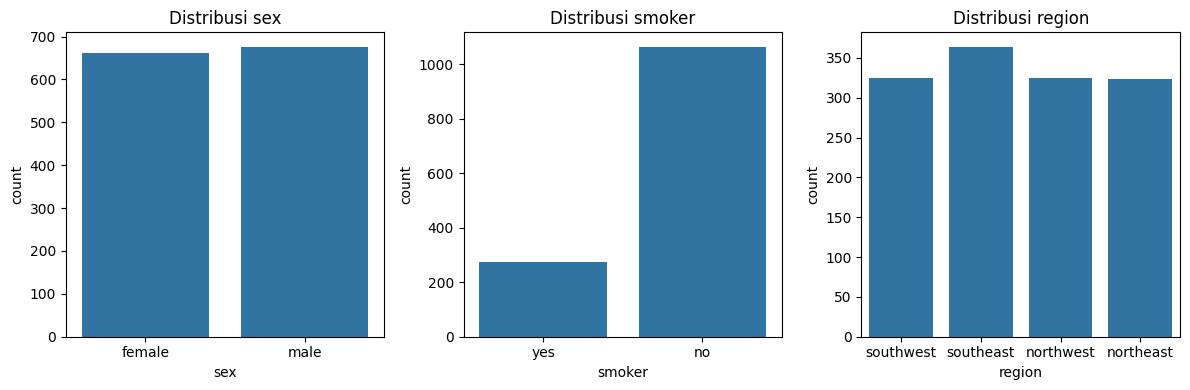

In [53]:
#Analisis Data Kategorikal
categorical_cols = ["sex", "smoker", "region"]

plt.figure(figsize=(12, 4))
for i, col in enumerate(categorical_cols, 1):
    plt.subplot(1, 3, i)
    sns.countplot(x=col, data=df)
    plt.title(f"Distribusi {col}")

plt.tight_layout()
plt.show()

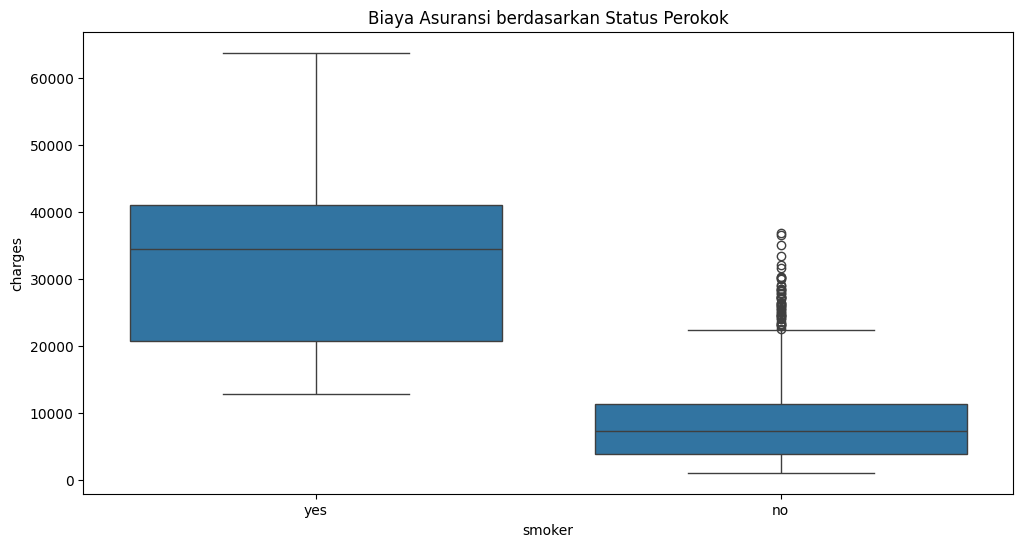

In [54]:
plt.figure(figsize=(12, 6))
sns.boxplot(x="smoker", y="charges", data=df)
plt.title("Biaya Asuransi berdasarkan Status Perokok")
plt.show()

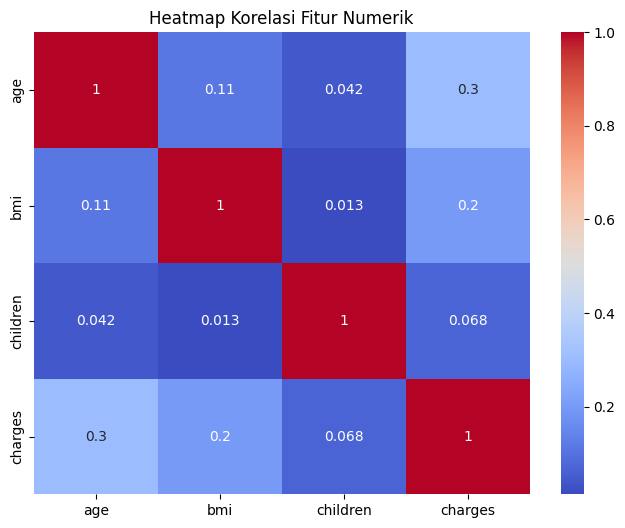

In [55]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[numerical_cols].corr(), annot=True, cmap="coolwarm")
plt.title("Heatmap Korelasi Fitur Numerik")
plt.show()


# **5. Data Preprocessing**

Pada tahap ini, data preprocessing adalah langkah penting untuk memastikan kualitas data sebelum digunakan dalam model machine learning.

Jika Anda menggunakan data teks, data mentah sering kali mengandung nilai kosong, duplikasi, atau rentang nilai yang tidak konsisten, yang dapat memengaruhi kinerja model. Oleh karena itu, proses ini bertujuan untuk membersihkan dan mempersiapkan data agar analisis berjalan optimal.

Berikut adalah tahapan-tahapan yang bisa dilakukan, tetapi **tidak terbatas** pada:
1. Menghapus atau Menangani Data Kosong (Missing Values)
2. Menghapus Data Duplikat
3. Normalisasi atau Standarisasi Fitur
4. Deteksi dan Penanganan Outlier
5. Encoding Data Kategorikal
6. Binning (Pengelompokan Data)

Cukup sesuaikan dengan karakteristik data yang kamu gunakan yah. Khususnya ketika kami menggunakan data tidak terstruktur.

### Cek dan Menghapus Data Duplikat

In [56]:
# Cek jumlah data duplikat
df.duplicated().sum()

np.int64(1)

In [57]:
# Hapus data duplikat
df = df.drop_duplicates()

### Deteksi Outlier

In [58]:
numerical_cols = ["age", "bmi", "children", "charges"]

Q1 = df[numerical_cols].quantile(0.25)
Q3 = df[numerical_cols].quantile(0.75)
IQR = Q3 - Q1

df_outlier_removed = df[~((df[numerical_cols] < (Q1 - 1.5 * IQR)) |
                           (df[numerical_cols] > (Q3 + 1.5 * IQR))).any(axis=1)]

print("Jumlah data sebelum outlier removal:", df.shape[0])
print("Jumlah data sesudah outlier removal:", df_outlier_removed.shape[0])


Jumlah data sebelum outlier removal: 1337
Jumlah data sesudah outlier removal: 1192


In [59]:
# Gunakan data tanpa outlier
df = df_outlier_removed.copy()

### Encoding Data Kategorikal

In [60]:
categorical_cols = ["sex", "smoker", "region"]

df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)
df_encoded.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,False,True,False,False,True
1,18,33.770,1,1725.55230,True,False,False,True,False
2,28,33.000,3,4449.46200,True,False,False,True,False
3,33,22.705,0,21984.47061,True,False,True,False,False
4,32,28.880,0,3866.85520,True,False,True,False,False


### Pemisahan Fitur dan Target

In [61]:
X = df_encoded.drop("charges", axis=1)
y = df_encoded["charges"]

### Normalisasi / Standarisasi Fitur

In [62]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled


array([[-1.42321022, -0.35760817, -0.89354491, ..., -0.58510028,
        -0.58251682,  1.75960789],
       [-1.4943767 ,  0.64292911, -0.0710696 , ..., -0.58510028,
         1.71668863, -0.56830843],
       [-0.78271189,  0.51168316,  1.57388104, ..., -0.58510028,
         1.71668863, -0.56830843],
       ...,
       [-1.4943767 ,  1.16791289, -0.89354491, ..., -0.58510028,
         1.71668863, -0.56830843],
       [-1.28087726, -0.71555166, -0.89354491, ..., -0.58510028,
        -0.58251682,  1.75960789],
       [ 1.565782  , -0.15818251, -0.89354491, ...,  1.70910872,
        -0.58251682, -0.56830843]])

In [63]:
preprocessed_df = pd.DataFrame(X_scaled, columns=X.columns)
preprocessed_df["charges"] = y.values

output_candidates = [
    Path("../preprocessing/insurance_preprocessing/insurance_preprocessed.csv"),
    Path("preprocessing/insurance_preprocessing/insurance_preprocessed.csv")
]
output_path = next(path for path in output_candidates if path.parent.exists())
preprocessed_df.to_csv(output_path, index=False)

print("Dataset preprocessing berhasil disimpan.")

Dataset preprocessing berhasil disimpan.


# **6. Pemodelan Regresi dan Perbandingan Outlier**

Pada tahap ini dibuat model `LinearRegression` untuk membandingkan performa pada data dengan outlier dan data tanpa outlier. Preprocessing dilakukan menggunakan `Pipeline` agar encoder dan scaler hanya dipelajari dari data training dan tidak terjadi data leakage.

In [64]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Muat ulang data mentah agar dua skenario dapat dibandingkan
df_model = pd.read_csv(file_path).drop_duplicates().copy()

numerical_cols = ["age", "bmi", "children"]
categorical_cols = ["sex", "smoker", "region"]
outlier_cols = numerical_cols + ["charges"]

Q1 = df_model[outlier_cols].quantile(0.25)
Q3 = df_model[outlier_cols].quantile(0.75)
IQR = Q3 - Q1

df_without_outliers = df_model[~((df_model[outlier_cols] < (Q1 - 1.5 * IQR)) |
                                  (df_model[outlier_cols] > (Q3 + 1.5 * IQR))).any(axis=1)].copy()

print(f"Data dengan outlier: {len(df_model)} baris")
print(f"Data tanpa outlier: {len(df_without_outliers)} baris")

Data dengan outlier: 1337 baris
Data tanpa outlier: 1192 baris


In [65]:
def evaluate_regression(data):
    X = data.drop("charges", axis=1)
    y = data["charges"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), numerical_cols),
            ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_cols)
        ]
    )

    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    return {
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    }

In [66]:
results = pd.DataFrame({
    "Dengan Outlier": evaluate_regression(df_model),
    "Tanpa Outlier": evaluate_regression(df_without_outliers)
}).T

results.index.name = "Skenario"
results.round(3)

,MAE,RMSE,R2
Skenario,,,
Dengan Outlier,4177.046,5956.343,0.807
Tanpa Outlier,2752.138,4827.747,0.600


### Interpretasi Hasil

- MAE dan RMSE yang lebih kecil menunjukkan kesalahan prediksi yang lebih rendah.
- RMSE memberikan penalti lebih besar terhadap kesalahan prediksi yang ekstrem.
- R² yang lebih besar menunjukkan proporsi variasi `charges` yang lebih banyak dapat dijelaskan oleh model.
- Perbandingan perlu mempertimbangkan bahwa data tanpa outlier memiliki jumlah observasi yang berbeda. Nilai biaya ekstrem juga dapat merupakan kasus nyata, sehingga penghapusannya perlu dibenarkan berdasarkan tujuan analisis.